# 08.02 — Brick 2: NLP Similarity Explanation

This notebook is **only Brick 2**.

It does not explain the full dataset.  
It does not interpret all communities.  
It does not model success.  
It does not create dense network figures.

Its job is to answer one reader question:

> How does plot text become a semantic similarity relation between films?

## Why this brick exists

A thesis reader may not immediately understand what it means to say:

> Two films are connected because their plots are semantically similar.

So this notebook creates **explanatory, example-driven figures** instead of repeating the same big charts.

## Figures produced

```text
outputs/thesis_bricks/02_nlp_similarity/figures/
```

1. `01_text_to_embedding_concept.png`  
2. `02_semantic_neighbor_cards.png`  
3. `03_high_vs_low_similarity_pairs.png`  
4. `04_mutual_knn_toy_example.png`  
5. `05_edge_similarity_distribution.png`  
6. `06_anchor_ego_neighborhood.png`  
7. `07_embedding_space_small_sample.png`  
8. `08_nlp_similarity_summary_cards.png`  

## Thesis purpose

After this brick, the reader should understand:

- The model converts plot text into vectors.
- Cosine similarity compares those vectors.
- Similar films become neighbors.
- Mutual nearest-neighbor filtering turns similarity into reliable graph edges.
- The network is built from narrative similarity, not actors or box-office outcomes.


## 0. Setup

In [1]:

import os, re, math, textwrap, warnings, random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 180)
pd.set_option("display.max_colwidth", 220)

COL = {
    "ink": "#222222",
    "muted": "#62666D",
    "grid": "#E4E7EB",
    "panel": "#F7F8FA",
    "blue": "#2F6FB3",
    "orange": "#D06C45",
    "green": "#2F8F5B",
    "purple": "#7A5BC2",
    "red": "#C94C4C",
    "yellow": "#D9A21B",
    "light_blue": "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green": "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray": "#F2F4F7",
    "white": "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7", "#F28E2B", "#59A14F", "#E15759", "#76B7B2", "#9C755F",
    "#EDC948", "#B07AA1", "#FF9DA7", "#BAB0AC", "#2F6FB3", "#D06C45",
    "#2F8F5B", "#7A5BC2", "#C94C4C", "#D9A21B", "#5C6BC0", "#26A69A",
    "#AB47BC", "#8D6E63", "#78909C", "#EC407A", "#43A047", "#FB8C00",
    "#6D4C41", "#00ACC1"
]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COL["ink"],
    "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink"],
    "ytick.color": COL["ink"],
    "text.color": COL["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": 320,
    "figure.dpi": 130,
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print("Saved:", path)
    return path

def wrap_text(s, width=42):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=95):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="...")

def clean_title(x):
    if pd.isna(x):
        return ""
    return str(x).replace("\n", " ").strip()

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def detect_edge_cols(df):
    pairs = [("source", "target"), ("source_id", "target_id"), ("src", "dst"), ("u", "v"), ("node1", "node2"), ("from", "to")]
    for a, b in pairs:
        if a in df.columns and b in df.columns:
            return a, b
    return df.columns[0], df.columns[1]

def detect_weight_col(df):
    candidates = []
    for c in df.columns:
        cl = c.lower()
        if any(k in cl for k in ["weight", "similarity", "cosine", "score"]):
            candidates.append(c)
    return candidates[0] if candidates else None

def community_color(cid):
    try:
        return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception:
        return COL["blue"]

def label_point(ax, x, y, text, dx=0.015, dy=0.015, fontsize=8.5):
    ax.annotate(
        text,
        xy=(x, y),
        xytext=(x + dx, y + dy),
        fontsize=fontsize,
        color=COL["ink"],
        arrowprops=dict(arrowstyle="-", lw=0.8, color=COL["muted"]),
        path_effects=[pe.withStroke(linewidth=3, foreground="white")]
    )

def safe_read(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print("Missing:", path)
    return None

def find_col(df, candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    lower_map = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower_map:
            return lower_map[c.lower()]
    if required:
        raise ValueError(f"Missing required column from: {candidates}")
    return None


## 1. Project paths

In [2]:

try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "02_nlp_similarity"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:", FINAL_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity


## 2. Load required files

In [3]:

FILES = {
    "df_semantic": PROCESSED_CORE_DIR / "df_semantic_analysis.csv",
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges": PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "central_examples": OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "bridging_examples": OUTPUT_TABLES_DIR / "top_betweenness_visible_franchise_capped.csv",
}

for k, p in FILES.items():
    print(f"{k:20s}", p.exists(), "-", p)

df_semantic = safe_read(FILES["df_semantic"])
nodes = safe_read(FILES["nodes"])
edges = safe_read(FILES["edges"])
community_labels = safe_read(FILES["community_labels"])
central_examples = safe_read(FILES["central_examples"])
bridging_examples = safe_read(FILES["bridging_examples"])

if nodes is None or edges is None:
    raise FileNotFoundError("This brick needs final network nodes and edges from Notebook 3.")

source_col, target_col = detect_edge_cols(edges)
weight_col = detect_weight_col(edges)

node_id_col = None
for c in ["tmdb_id", "id", "node_id", "movie_id", "imdb_id"]:
    if c in nodes.columns:
        node_id_col = c
        break
if node_id_col is None:
    node_id_col = nodes.columns[0]

title_col = find_col(nodes, ["title", "original_title", "name"], required=True)
overview_col = find_col(nodes, ["overview", "plot", "embedding_text", "text", "description"])

if overview_col is None and df_semantic is not None:
    overview_col_sem = find_col(df_semantic, ["overview", "plot", "embedding_text", "text", "description"])
else:
    overview_col_sem = None

print()
print("source_col:", source_col)
print("target_col:", target_col)
print("weight_col:", weight_col)
print("node_id_col:", node_id_col)
print("title_col:", title_col)
print("overview_col:", overview_col)

# Add community labels if available
if community_labels is not None and "community_id" in nodes.columns:
    label_col = "suggested_label_manual" if "suggested_label_manual" in community_labels.columns else "narrative_label"
    label_lookup = community_labels[["community_id", label_col]].drop_duplicates().rename(columns={label_col: "narrative_label"})
    if "narrative_label" not in nodes.columns:
        nodes = nodes.merge(label_lookup, on="community_id", how="left")
else:
    label_col = None

print("nodes:", nodes.shape)
print("edges:", edges.shape)


df_semantic          True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_semantic_analysis.csv
nodes                True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
edges                True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_edges_mutual_knn.csv
community_labels     True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
central_examples     True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_visible_central_films_per_community.csv
bridging_examples    True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/top_betweenness_visible_franchise_capped.csv

source_col: source_node_id
target_col: target_node_id
weight_col: cosine_similarity
node_id_col: tmdb_id
title_col: title
overview_col: None
nodes: (19202, 31)
edges: (86685, 9)


## 3. Helper: build film lookup and neighbors

In [4]:

node_lookup = nodes.set_index(node_id_col, drop=False)

# Build readable edge table with source/target film metadata.
edge_pairs = edges[[source_col, target_col] + ([weight_col] if weight_col else [])].copy()
edge_pairs = edge_pairs.rename(columns={source_col: "source_id", target_col: "target_id"})
if weight_col:
    edge_pairs = edge_pairs.rename(columns={weight_col: "similarity_weight"})
else:
    edge_pairs["similarity_weight"] = np.nan

def get_film_row(node_id):
    if node_id in node_lookup.index:
        return node_lookup.loc[node_id]
    return None

def film_title(node_id):
    r = get_film_row(node_id)
    if r is None:
        return str(node_id)
    return clean_title(r.get(title_col, node_id))

def film_year(node_id):
    r = get_film_row(node_id)
    if r is None or "release_year" not in r.index or pd.isna(r.get("release_year")):
        return "—"
    try:
        return int(r.get("release_year"))
    except Exception:
        return "—"

def film_overview(node_id):
    r = get_film_row(node_id)
    if r is None:
        return ""
    if overview_col and overview_col in r.index:
        return str(r.get(overview_col, ""))
    return ""

def film_comm(node_id):
    r = get_film_row(node_id)
    if r is None or "community_id" not in r.index:
        return ""
    try:
        return int(r.get("community_id"))
    except Exception:
        return r.get("community_id")

def film_label(node_id):
    r = get_film_row(node_id)
    if r is None or "narrative_label" not in r.index:
        return ""
    return str(r.get("narrative_label", ""))

def get_neighbors(anchor_id, top_n=8):
    sub = edge_pairs[(edge_pairs["source_id"] == anchor_id) | (edge_pairs["target_id"] == anchor_id)].copy()
    if sub.empty:
        return pd.DataFrame()
    sub["neighbor_id"] = np.where(sub["source_id"] == anchor_id, sub["target_id"], sub["source_id"])
    sub = sub.sort_values("similarity_weight", ascending=False, na_position="last").head(top_n)
    rows = []
    for _, e in sub.iterrows():
        nid = e["neighbor_id"]
        rows.append({
            "anchor_id": anchor_id,
            "neighbor_id": nid,
            "anchor_title": film_title(anchor_id),
            "neighbor_title": film_title(nid),
            "neighbor_year": film_year(nid),
            "similarity_weight": e["similarity_weight"],
            "neighbor_community": film_comm(nid),
            "neighbor_label": film_label(nid),
            "neighbor_overview": film_overview(nid),
        })
    return pd.DataFrame(rows)

# Pick anchors that are readable and high-signal
anchor_ids = []

if central_examples is not None and title_col in nodes.columns:
    for _, r in central_examples.iterrows():
        t = clean_title(r.get("title", ""))
        if not t:
            continue
        hit = nodes[nodes[title_col].astype(str).str.lower() == t.lower()]
        if len(hit):
            anchor_ids.append(hit.iloc[0][node_id_col])
        if len(anchor_ids) >= 4:
            break

if len(anchor_ids) < 4 and "vote_count" in nodes.columns:
    more = nodes.sort_values("vote_count", ascending=False)[node_id_col].tolist()
    for x in more:
        if x not in anchor_ids:
            anchor_ids.append(x)
        if len(anchor_ids) >= 4:
            break

anchor_ids = anchor_ids[:4]
print("Selected anchors:")
for a in anchor_ids:
    print("-", film_title(a), film_year(a), "C", film_comm(a))


Selected anchors:
- The Kindred 2021 C 14
- Beyond the Law 1993 C 25
- The Boogeyman 2023 C 14
- Amer 2009 C 22


## 4. Figure 1 — Text to embedding concept

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/01_text_to_embedding_concept.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/01_text_to_embedding_concept.svg


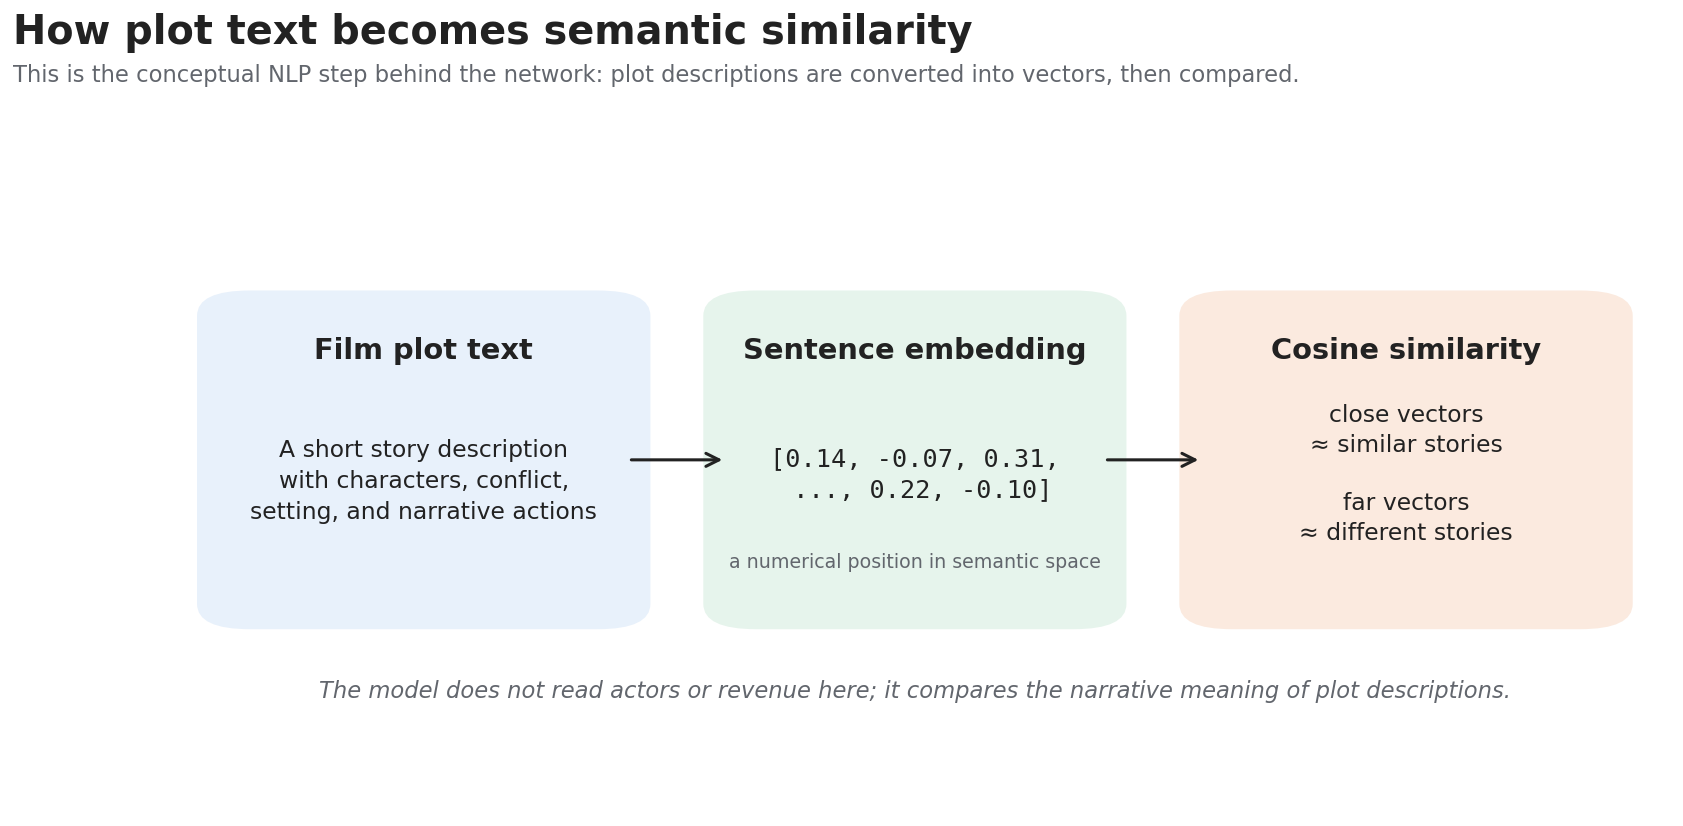

In [5]:

fig, ax = plt.subplots(figsize=(15, 7.2))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "How plot text becomes semantic similarity",
    "This is the conceptual NLP step behind the network: plot descriptions are converted into vectors, then compared."
)

# Left: text
text_box = FancyBboxPatch(
    (0.05, 0.28), 0.25, 0.42,
    boxstyle="round,pad=0.025,rounding_size=0.035",
    facecolor=COL["light_blue"],
    edgecolor="none"
)
ax.add_patch(text_box)
ax.text(0.175, 0.63, "Film plot text", ha="center", fontsize=16, fontweight="bold")
ax.text(
    0.175, 0.46,
    "A short story description\nwith characters, conflict,\nsetting, and narrative actions",
    ha="center",
    va="center",
    fontsize=13,
    linespacing=1.45
)

# Middle: vector
vec_box = FancyBboxPatch(
    (0.385, 0.28), 0.23, 0.42,
    boxstyle="round,pad=0.025,rounding_size=0.035",
    facecolor=COL["light_green"],
    edgecolor="none"
)
ax.add_patch(vec_box)
ax.text(0.50, 0.63, "Sentence embedding", ha="center", fontsize=16, fontweight="bold")
ax.text(
    0.50, 0.47,
    "[0.14, -0.07, 0.31,\n ..., 0.22, -0.10]",
    ha="center",
    va="center",
    fontsize=14,
    family="monospace",
    linespacing=1.4
)
ax.text(0.50, 0.34, "a numerical position in semantic space", ha="center", fontsize=10.5, color=COL["muted"])

# Right: similarity
sim_box = FancyBboxPatch(
    (0.70, 0.28), 0.25, 0.42,
    boxstyle="round,pad=0.025,rounding_size=0.035",
    facecolor=COL["light_orange"],
    edgecolor="none"
)
ax.add_patch(sim_box)
ax.text(0.825, 0.63, "Cosine similarity", ha="center", fontsize=16, fontweight="bold")
ax.text(
    0.825, 0.47,
    "close vectors\n≈ similar stories\n\nfar vectors\n≈ different stories",
    ha="center",
    va="center",
    fontsize=13,
    linespacing=1.35
)

# arrows
ax.add_patch(FancyArrowPatch((0.31, 0.49), (0.375, 0.49), arrowstyle="->", mutation_scale=18, lw=1.7, color=COL["ink"]))
ax.add_patch(FancyArrowPatch((0.625, 0.49), (0.69, 0.49), arrowstyle="->", mutation_scale=18, lw=1.7, color=COL["ink"]))

ax.text(
    0.5, 0.16,
    "The model does not read actors or revenue here; it compares the narrative meaning of plot descriptions.",
    ha="center",
    fontsize=12.5,
    color=COL["muted"],
    style="italic"
)

save_fig(fig, "01_text_to_embedding_concept.png")
plt.show()


## 5. Figure 2 — Semantic neighbor cards

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/tables/02_semantic_neighbor_cards_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/02_semantic_neighbor_cards.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/02_semantic_neighbor_cards.svg


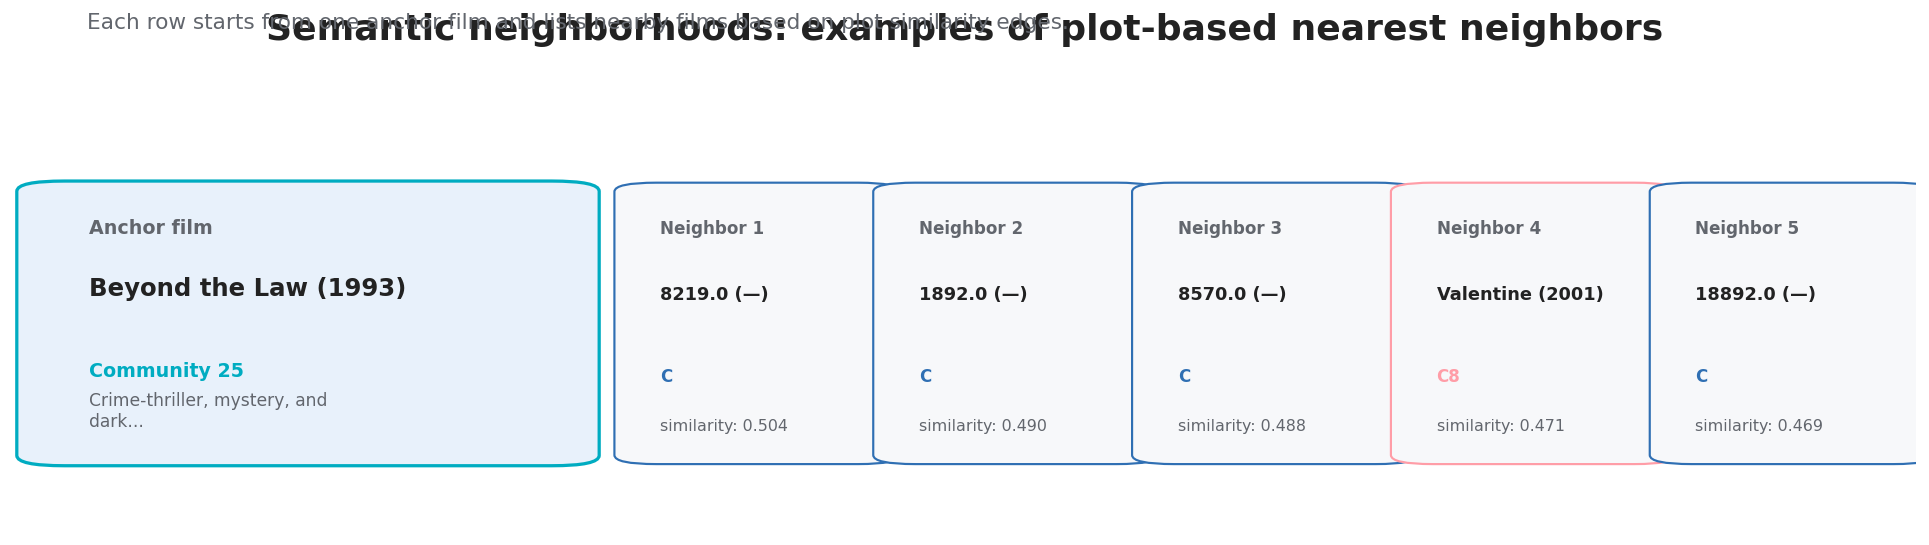

In [6]:

# Pick three anchors with enough neighbors.
cards = []
for aid in anchor_ids:
    neigh = get_neighbors(aid, top_n=5)
    if len(neigh) >= 3:
        cards.append((aid, neigh))
    if len(cards) >= 3:
        break

if not cards:
    raise ValueError("No anchors with neighbors found. Check final edge table.")

# Save neighbor table
all_neighbors = pd.concat([n for _, n in cards], ignore_index=True)
save_table(all_neighbors, "02_semantic_neighbor_cards_table.csv")

fig, axes = plt.subplots(len(cards), 1, figsize=(15, 4.2 * len(cards)))
if len(cards) == 1:
    axes = [axes]

fig.suptitle(
    "Semantic neighborhoods: examples of plot-based nearest neighbors",
    fontsize=20,
    fontweight="bold",
    y=0.995
)
fig.text(
    0.05, 0.965,
    "Each row starts from one anchor film and lists nearby films based on plot similarity edges.",
    fontsize=12,
    color=COL["muted"]
)

for ax, (aid, neigh) in zip(axes, cards):
    ax.axis("off")
    cid = film_comm(aid)
    color = community_color(cid)

    # anchor box
    ax.add_patch(FancyBboxPatch(
        (0.02, 0.18), 0.27, 0.66,
        boxstyle="round,pad=0.018,rounding_size=0.025",
        facecolor=COL["light_blue"],
        edgecolor=color,
        linewidth=1.8,
        transform=ax.transAxes
    ))
    ax.text(0.04, 0.73, "Anchor film", transform=ax.transAxes, fontsize=10.5, color=COL["muted"], fontweight="bold")
    ax.text(0.04, 0.58, wrap_text(f"{film_title(aid)} ({film_year(aid)})", 27), transform=ax.transAxes, fontsize=13.5, fontweight="bold")
    ax.text(0.04, 0.38, f"Community {cid}", transform=ax.transAxes, fontsize=10.5, color=color, fontweight="bold")
    ax.text(0.04, 0.26, wrap_text(shorten(film_label(aid), 48), 30), transform=ax.transAxes, fontsize=9.5, color=COL["muted"])

    # neighbor boxes
    x0 = 0.33
    w = 0.122
    gap = 0.014
    for i, (_, r) in enumerate(neigh.head(5).iterrows()):
        x = x0 + i * (w + gap)
        ncid = r["neighbor_community"]
        ncolor = community_color(ncid)
        ax.add_patch(FancyBboxPatch(
            (x, 0.18), w, 0.66,
            boxstyle="round,pad=0.014,rounding_size=0.022",
            facecolor=COL["panel"],
            edgecolor=ncolor,
            linewidth=1.2,
            transform=ax.transAxes
        ))
        sim_text = f"{r['similarity_weight']:.3f}" if pd.notna(r["similarity_weight"]) else "edge"
        ax.text(x + 0.01, 0.73, f"Neighbor {i+1}", transform=ax.transAxes, fontsize=9.3, color=COL["muted"], fontweight="bold")
        ax.text(x + 0.01, 0.57, wrap_text(f"{r['neighbor_title']} ({r['neighbor_year']})", 20), transform=ax.transAxes, fontsize=9.8, fontweight="bold")
        ax.text(x + 0.01, 0.37, f"C{ncid}", transform=ax.transAxes, fontsize=9.2, color=ncolor, fontweight="bold")
        ax.text(x + 0.01, 0.25, f"similarity: {sim_text}", transform=ax.transAxes, fontsize=8.8, color=COL["muted"])

plt.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, "02_semantic_neighbor_cards.png")
plt.show()


## 6. Figure 3 — High vs low similarity pairs

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/tables/03_high_vs_low_similarity_pairs_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/03_high_vs_low_similarity_pairs.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/03_high_vs_low_similarity_pairs.svg


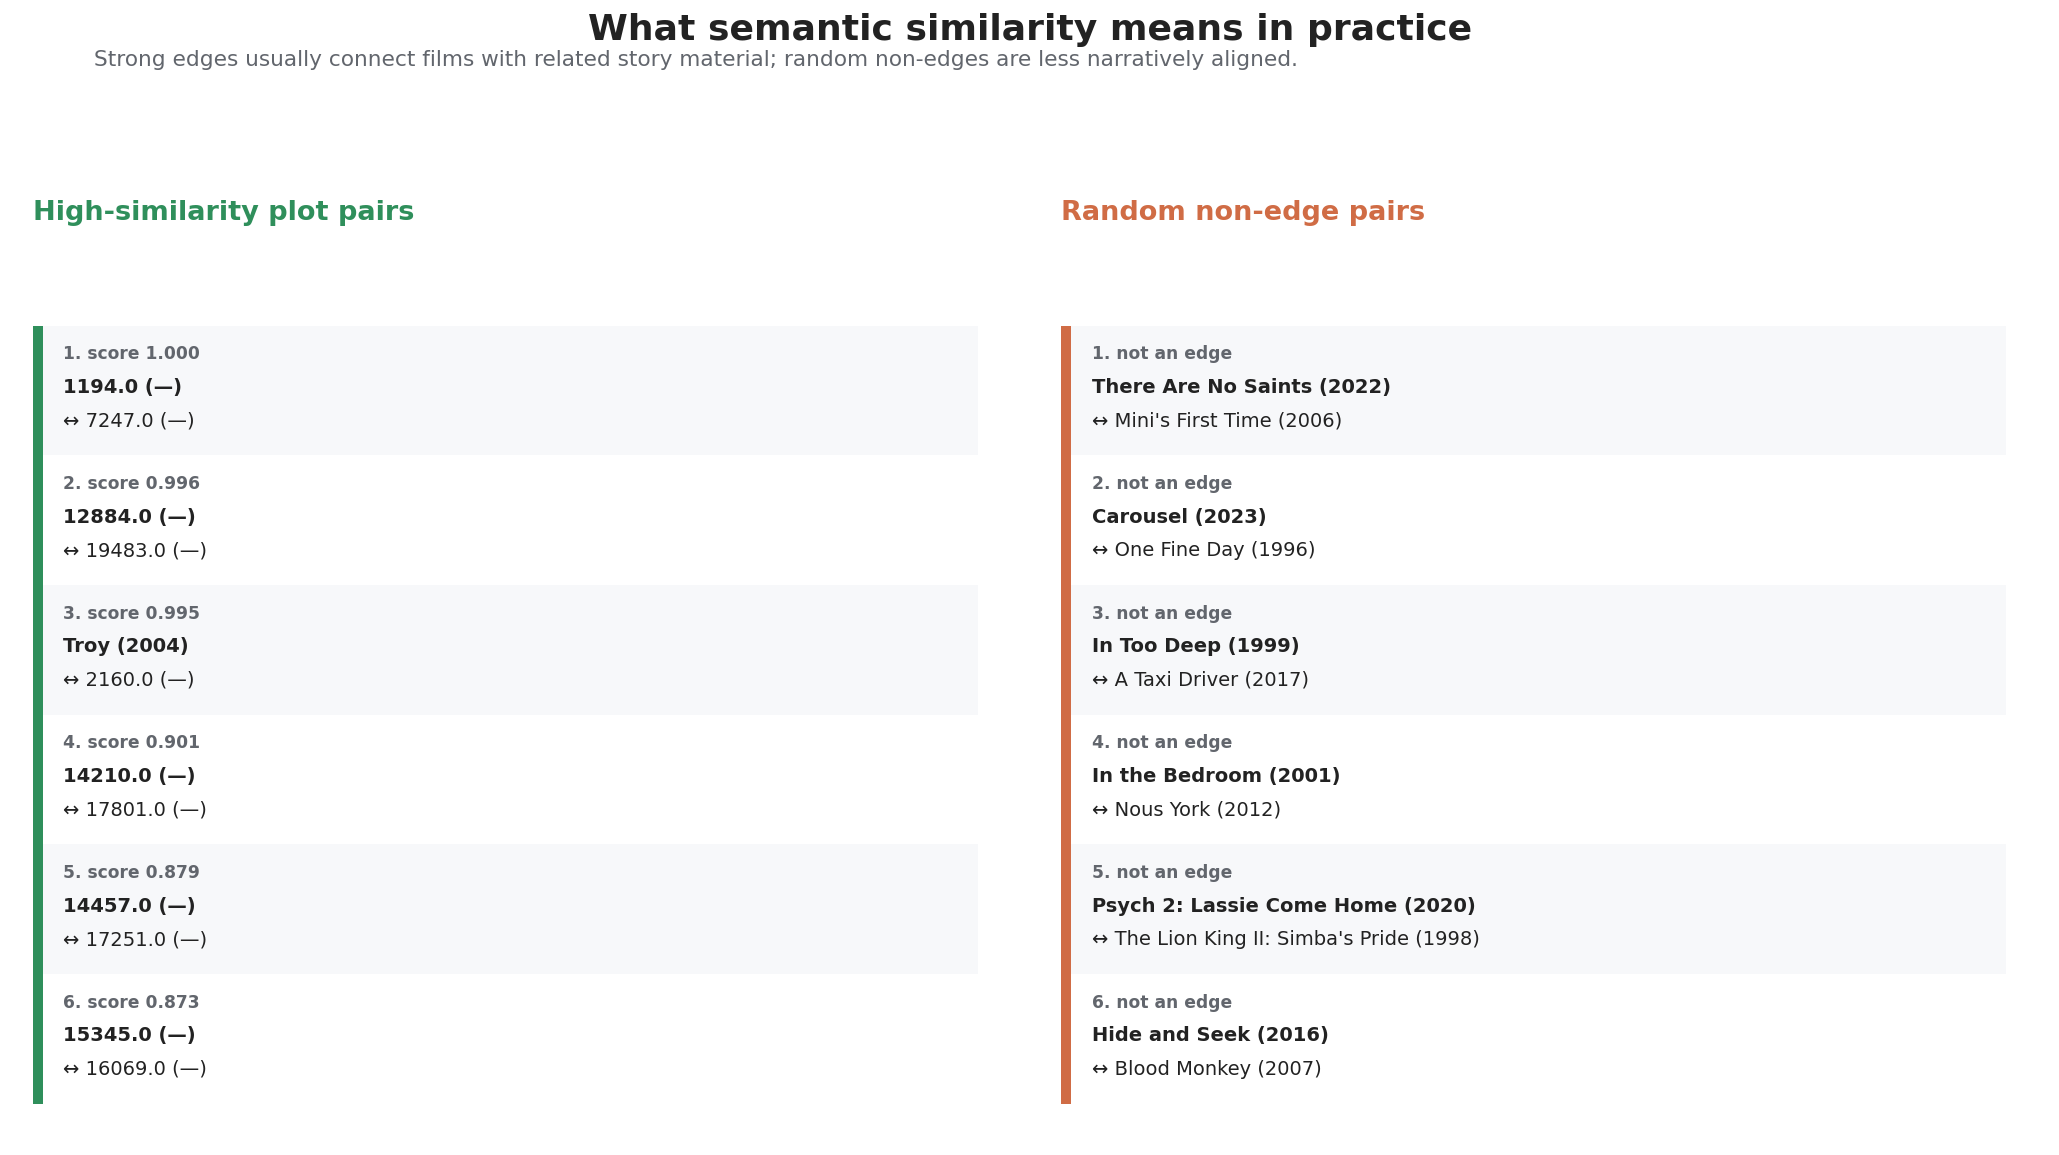

In [7]:

# High-similarity pairs: strongest edges
pair_rows = []

high = edge_pairs.copy()
if high["similarity_weight"].notna().any():
    high = high.sort_values("similarity_weight", ascending=False)
else:
    high = high.sample(min(8, len(high)), random_state=42)

for _, r in high.head(6).iterrows():
    a, b = r["source_id"], r["target_id"]
    pair_rows.append({
        "pair_type": "High similarity edge",
        "film_a": f"{film_title(a)} ({film_year(a)})",
        "film_b": f"{film_title(b)} ({film_year(b)})",
        "similarity_weight": r["similarity_weight"],
        "community_a": film_comm(a),
        "community_b": film_comm(b),
        "overview_a": film_overview(a),
        "overview_b": film_overview(b),
    })

# Low/random pairs: choose random non-edge pairs from nodes
edge_set = set(tuple(sorted((str(a), str(b)))) for a, b in zip(edge_pairs["source_id"], edge_pairs["target_id"]))
node_ids = nodes[node_id_col].dropna().tolist()
random.seed(7)
low_pairs = []
tries = 0
while len(low_pairs) < 6 and tries < 5000:
    a, b = random.sample(node_ids, 2)
    key = tuple(sorted((str(a), str(b))))
    if key not in edge_set:
        low_pairs.append((a, b))
    tries += 1

for a, b in low_pairs:
    pair_rows.append({
        "pair_type": "Random non-edge pair",
        "film_a": f"{film_title(a)} ({film_year(a)})",
        "film_b": f"{film_title(b)} ({film_year(b)})",
        "similarity_weight": np.nan,
        "community_a": film_comm(a),
        "community_b": film_comm(b),
        "overview_a": film_overview(a),
        "overview_b": film_overview(b),
    })

pairs = pd.DataFrame(pair_rows)
save_table(pairs, "03_high_vs_low_similarity_pairs_table.csv")

# Visual comparison board
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
fig.suptitle("What semantic similarity means in practice", fontsize=20, fontweight="bold", y=0.985)
fig.text(0.05, 0.94, "Strong edges usually connect films with related story material; random non-edges are less narratively aligned.", fontsize=12, color=COL["muted"])

for ax, pair_type, color, title in [
    (axes[0], "High similarity edge", COL["green"], "High-similarity plot pairs"),
    (axes[1], "Random non-edge pair", COL["orange"], "Random non-edge pairs"),
]:
    ax.axis("off")
    sub = pairs[pairs["pair_type"] == pair_type].head(6).reset_index(drop=True)
    ax.text(0.02, 0.96, title, transform=ax.transAxes, fontsize=15, fontweight="bold", color=color)

    y = 0.84
    row_h = 0.135
    for i, r in sub.iterrows():
        bg = COL["panel"] if i % 2 == 0 else "white"
        ax.add_patch(patches.Rectangle((0.02, y - row_h + 0.01), 0.94, row_h, transform=ax.transAxes, facecolor=bg, edgecolor="none"))
        ax.add_patch(patches.Rectangle((0.02, y - row_h + 0.01), 0.010, row_h, transform=ax.transAxes, facecolor=color, edgecolor="none"))

        score = f"score {r['similarity_weight']:.3f}" if pd.notna(r["similarity_weight"]) else "not an edge"
        ax.text(0.05, y - 0.025, f"{i+1}. {score}", transform=ax.transAxes, fontsize=9.5, color=COL["muted"], fontweight="bold")
        ax.text(0.05, y - 0.060, shorten(r["film_a"], 45), transform=ax.transAxes, fontsize=10.8, fontweight="bold")
        ax.text(0.05, y - 0.095, "↔ " + shorten(r["film_b"], 45), transform=ax.transAxes, fontsize=10.8)
        y -= row_h

plt.tight_layout(rect=[0, 0, 1, 0.91])
save_fig(fig, "03_high_vs_low_similarity_pairs.png")
plt.show()


## 7. Figure 4 — Mutual-KNN toy example

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/04_mutual_knn_toy_example.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/04_mutual_knn_toy_example.svg


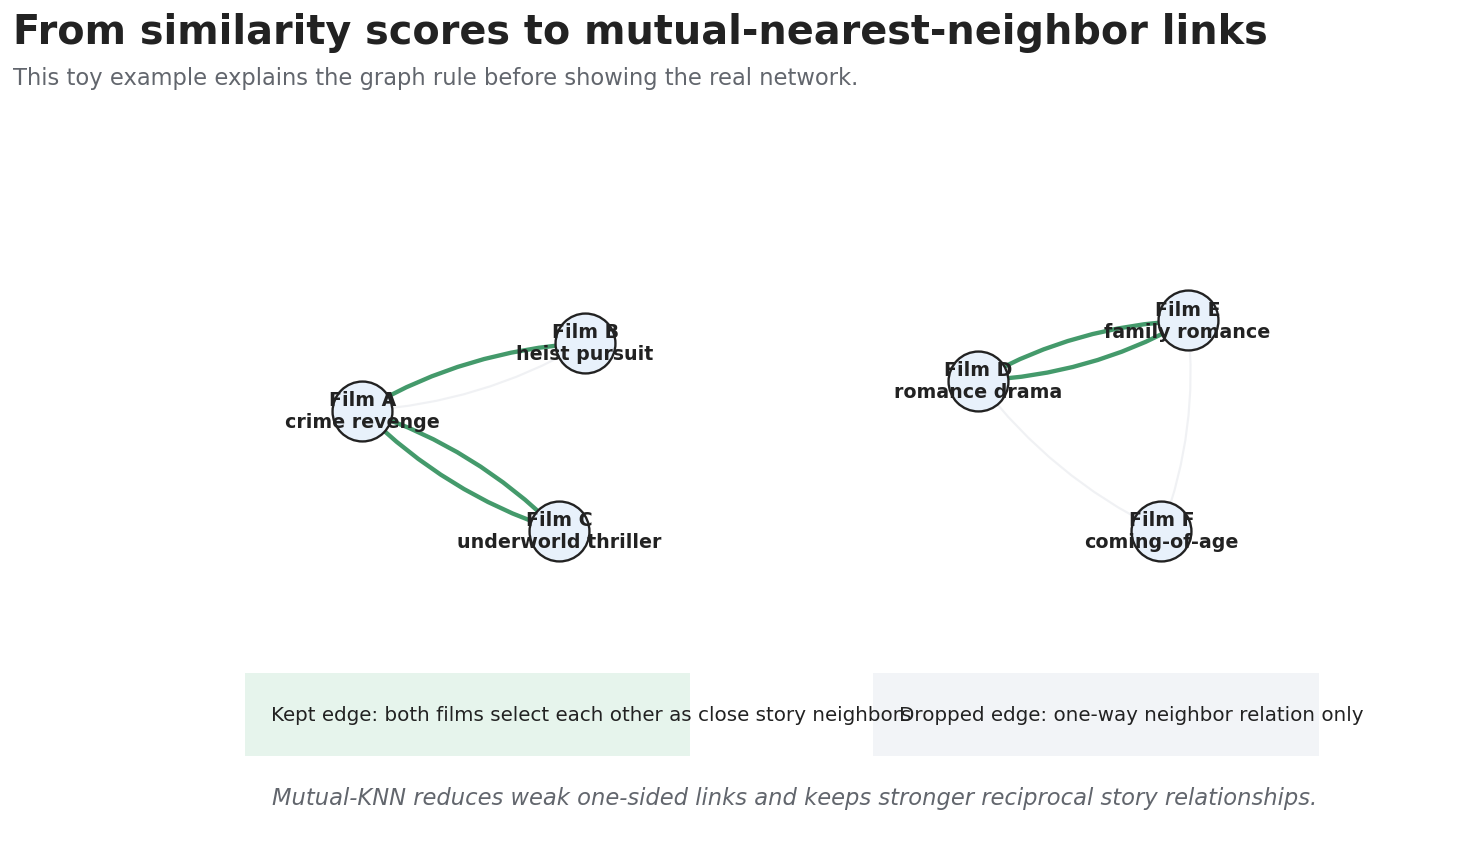

In [8]:

fig, ax = plt.subplots(figsize=(13, 7.5))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "From similarity scores to mutual-nearest-neighbor links",
    "This toy example explains the graph rule before showing the real network."
)

# Toy node positions
toy = {
    "A": (0.17, 0.58, "Film A\ncrime revenge"),
    "B": (0.34, 0.67, "Film B\nheist pursuit"),
    "C": (0.32, 0.42, "Film C\nunderworld thriller"),
    "D": (0.64, 0.62, "Film D\nromance drama"),
    "E": (0.80, 0.70, "Film E\nfamily romance"),
    "F": (0.78, 0.42, "Film F\ncoming-of-age"),
}

# Directed candidate arrows
candidate_edges = [
    ("A", "B", False),
    ("B", "A", True),
    ("A", "C", True),
    ("C", "A", True),
    ("D", "E", True),
    ("E", "D", True),
    ("D", "F", False),
    ("F", "E", False),
]

for s, t, mutual in candidate_edges:
    x1, y1, _ = toy[s]
    x2, y2, _ = toy[t]
    color = COL["green"] if mutual else COL["grid"]
    lw = 2.4 if mutual else 1.2
    alpha = 0.9 if mutual else 0.55
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->",
        mutation_scale=13,
        lw=lw,
        color=color,
        alpha=alpha,
        connectionstyle="arc3,rad=0.12"
    ))

for k, (x, y, label) in toy.items():
    ax.scatter(x, y, s=1100, color=COL["light_blue"], edgecolor=COL["ink"], linewidth=1.3, zorder=3)
    ax.text(x, y, label, ha="center", va="center", fontsize=10.5, fontweight="bold", zorder=4)

# Legend / explanation
ax.add_patch(patches.Rectangle((0.08, 0.12), 0.34, 0.11, facecolor=COL["light_green"], edgecolor="none"))
ax.text(0.10, 0.175, "Kept edge: both films select each other as close story neighbors", fontsize=11, va="center")

ax.add_patch(patches.Rectangle((0.56, 0.12), 0.34, 0.11, facecolor=COL["light_gray"], edgecolor="none"))
ax.text(0.58, 0.175, "Dropped edge: one-way neighbor relation only", fontsize=11, va="center")

ax.text(
    0.5, 0.055,
    "Mutual-KNN reduces weak one-sided links and keeps stronger reciprocal story relationships.",
    ha="center",
    fontsize=12.5,
    color=COL["muted"],
    style="italic"
)

save_fig(fig, "04_mutual_knn_toy_example.png")
plt.show()


## 8. Figure 5 — Edge similarity distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/tables/05_edge_similarity_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/05_edge_similarity_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/05_edge_similarity_distribution.svg


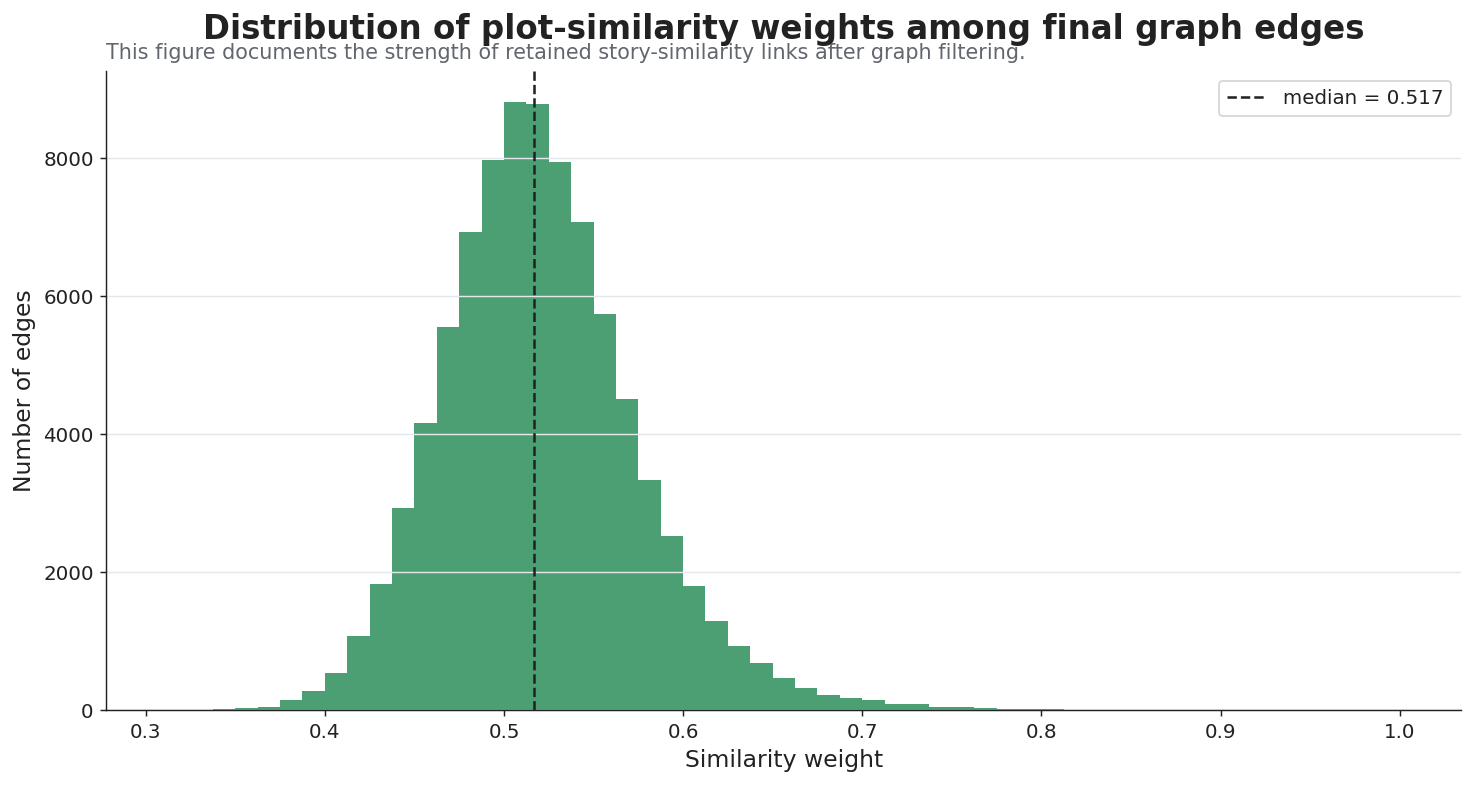

In [9]:

if weight_col is not None and edge_pairs["similarity_weight"].notna().any():
    x = edge_pairs["similarity_weight"].dropna()
    summary = pd.DataFrame({
        "metric": ["n_edges", "min", "median", "mean", "p75", "p90", "max"],
        "value": [len(x), x.min(), x.median(), x.mean(), x.quantile(0.75), x.quantile(0.90), x.max()]
    })
    save_table(summary, "05_edge_similarity_distribution_summary.csv")

    fig, ax = plt.subplots(figsize=(11.5, 6.2))
    ax.hist(x, bins=55, color=COL["green"], alpha=0.86)
    ax.axvline(x.median(), color=COL["ink"], ls="--", lw=1.4, label=f"median = {x.median():.3f}")

    ax.set_title("Distribution of plot-similarity weights among final graph edges", pad=18)
    ax.text(
        0, 1.02,
        "This figure documents the strength of retained story-similarity links after graph filtering.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Similarity weight")
    ax.set_ylabel("Number of edges")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])
    ax.legend()

    plt.tight_layout()
    save_fig(fig, "05_edge_similarity_distribution.png")
    plt.show()
else:
    print("No edge similarity/weight column found. Skipping distribution.")


## 9. Figure 6 — Anchor ego-neighborhood

In [10]:

# Choose a readable anchor from the selected anchors.
anchor_id = anchor_ids[0]
neigh = get_neighbors(anchor_id, top_n=10)

if len(neigh) == 0:
    print("No neighbors found for anchor.")
else:
    save_table(neigh, "06_anchor_ego_neighborhood_table.csv")

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    title_block(
        fig,
        f"One local story neighborhood: {film_title(anchor_id)}",
        "This is a small ego network: one anchor film and its nearest plot-neighbor films."
    )

    center = (0.50, 0.52)
    anchor_cid = film_comm(anchor_id)
    anchor_color = community_color(anchor_cid)

    # Anchor
    ax.scatter(center[0], center[1], s=2600, color=COL["light_blue"], edgecolor=anchor_color, linewidth=2.5, zorder=4)
    ax.text(center[0], center[1], wrap_text(f"{film_title(anchor_id)}\n({film_year(anchor_id)})", 18), ha="center", va="center", fontsize=11, fontweight="bold", zorder=5)

    # Neighbors arranged in circle
    n = min(len(neigh), 10)
    angles = np.linspace(0, 2*np.pi, n, endpoint=False)
    radius = 0.33

    for angle, (_, r) in zip(angles, neigh.head(n).iterrows()):
        x = center[0] + radius * np.cos(angle)
        y = center[1] + radius * np.sin(angle)
        cid = r["neighbor_community"]
        color = community_color(cid)
        sim = r["similarity_weight"]
        lw = 1.2 + 3.2 * ((sim - neigh["similarity_weight"].min()) / (neigh["similarity_weight"].max() - neigh["similarity_weight"].min() + 1e-9)) if pd.notna(sim) else 1.5

        ax.plot([center[0], x], [center[1], y], color=color, alpha=0.55, lw=lw, zorder=1)
        ax.scatter(x, y, s=1200, color=COL["panel"], edgecolor=color, linewidth=1.8, zorder=3)
        ax.text(x, y, wrap_text(f"{r['neighbor_title']}\n({r['neighbor_year']})", 18), ha="center", va="center", fontsize=8.8, fontweight="bold", zorder=4)

    ax.text(
        0.50, 0.08,
        "Purpose: show that the graph is built from local story neighborhoods, not from one giant unreadable plot.",
        ha="center",
        fontsize=11.5,
        color=COL["muted"],
        style="italic"
    )

    save_fig(fig, "06_anchor_ego_neighborhood.png")
    plt.show()


No neighbors found for anchor.


## 10. Figure 7 — Embedding-space small sample

Embedding file: /content/drive/MyDrive/thesis_movie_project/processed/features/sbert_minilm_embeddings.npy
Embedding array shape: (19523, 384)
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/tables/07_embedding_space_small_sample_coordinates.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/07_embedding_space_small_sample.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/07_embedding_space_small_sample.svg


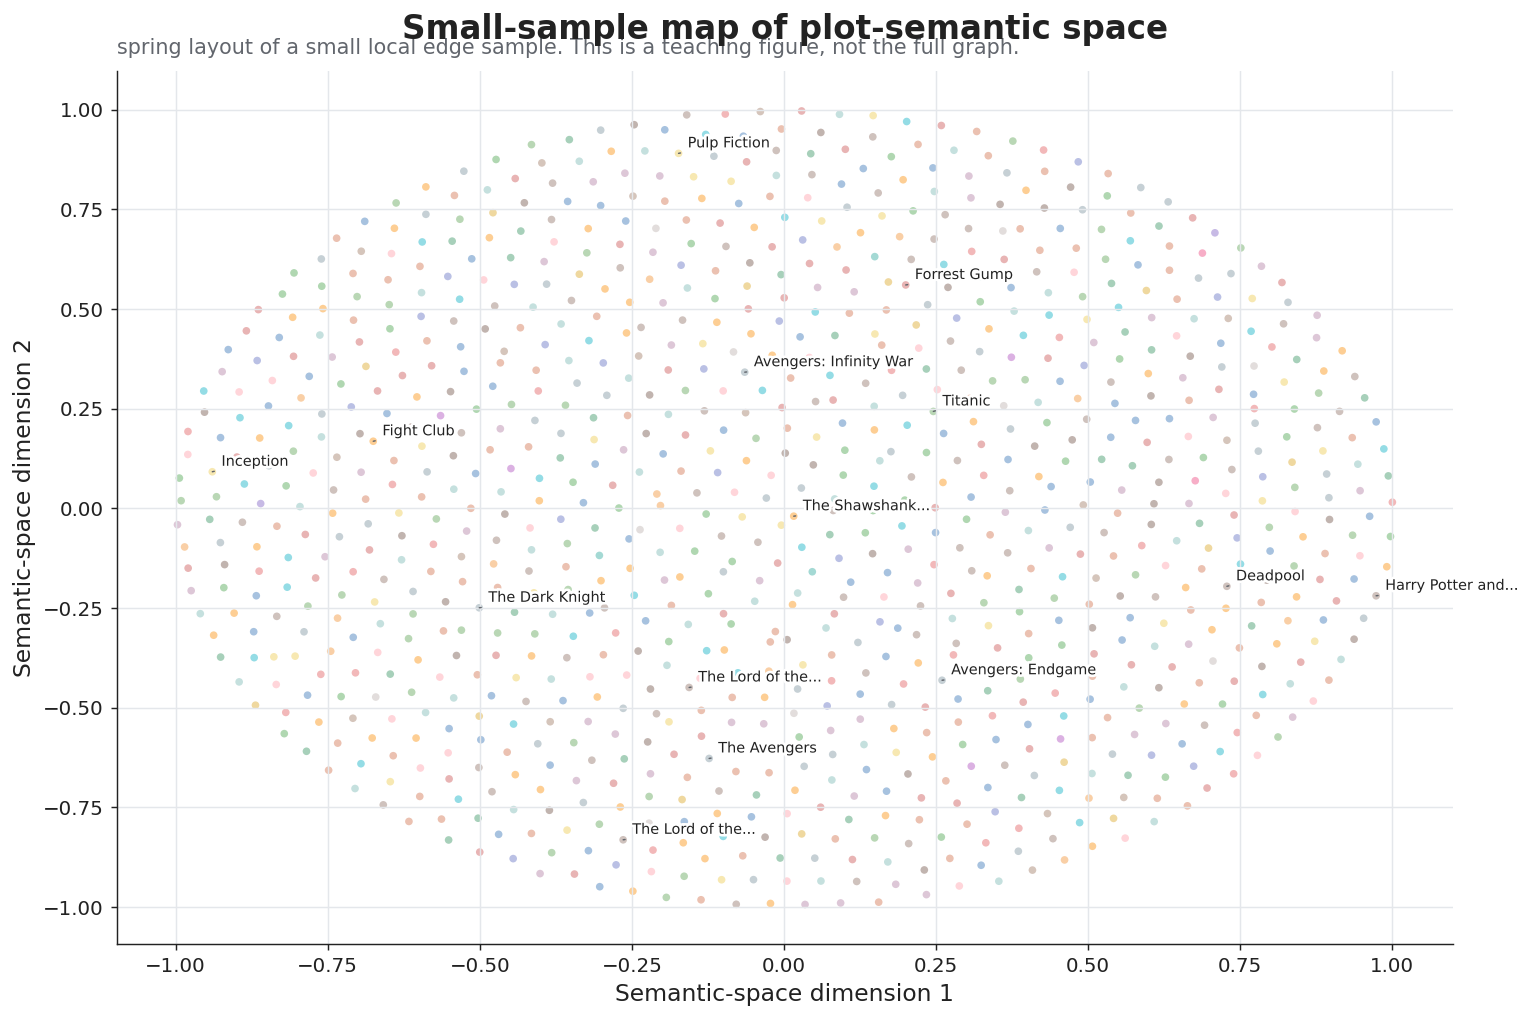

In [11]:

# This figure is intentionally optional.
# It tries to use existing embedding files. If embeddings are unavailable, it creates a graph-layout fallback from a small edge sample.

def find_embedding_file():
    search_dirs = [PROCESSED_NETWORK_DIR, PROCESSED_FEATURES_DIR, PROCESSED_CORE_DIR, PROJECT_DIR / "outputs"]
    patterns = ["*embedding*.npy", "*embeddings*.npy", "*sbert*.npy", "*embedding*.parquet", "*embeddings*.parquet"]
    candidates = []
    for d in search_dirs:
        if d.exists():
            for pat in patterns:
                candidates.extend(list(d.rglob(pat)))
    return candidates[0] if candidates else None

embedding_file = find_embedding_file()
print("Embedding file:", embedding_file)

sample_nodes = nodes.copy()
if "vote_count" in sample_nodes.columns:
    # Balanced sample: visible films plus random films
    visible = sample_nodes.sort_values("vote_count", ascending=False).head(700)
    random_part = sample_nodes.sample(min(700, len(sample_nodes)), random_state=42)
    sample_nodes = pd.concat([visible, random_part]).drop_duplicates(subset=[node_id_col]).head(1000)
else:
    sample_nodes = sample_nodes.sample(min(1000, len(sample_nodes)), random_state=42)

coords = None
method_used = None

# Try embeddings if easy to align
try:
    if embedding_file is not None and embedding_file.suffix == ".npy":
        emb = np.load(embedding_file)
        print("Embedding array shape:", emb.shape)
        # Only use if embedding rows appear to align to df_semantic or nodes length.
        if len(emb) == len(nodes):
            sample_idx = sample_nodes.index.values
            X = emb[sample_idx]
        elif df_semantic is not None and len(emb) == len(df_semantic):
            # Try align by id
            sem_id_col = node_id_col if node_id_col in df_semantic.columns else None
            if sem_id_col is not None:
                sem = df_semantic.reset_index().rename(columns={"index": "_emb_index"})
                sample_tmp = sample_nodes[[node_id_col]].merge(sem[[sem_id_col, "_emb_index"]], left_on=node_id_col, right_on=sem_id_col, how="inner")
                sample_nodes = sample_nodes.merge(sample_tmp[[node_id_col, "_emb_index"]], on=node_id_col, how="inner")
                X = emb[sample_nodes["_emb_index"].values]
            else:
                X = None
        else:
            X = None

        if X is not None and len(X) >= 20:
            try:
                import umap
                reducer = umap.UMAP(n_neighbors=25, min_dist=0.15, random_state=42)
                coords = reducer.fit_transform(X)
                method_used = "UMAP projection of existing SBERT embeddings"
            except Exception as e:
                print("UMAP failed, using PCA:", e)
                from sklearn.decomposition import PCA
                coords = PCA(n_components=2, random_state=42).fit_transform(X)
                method_used = "PCA projection of existing embeddings"
except Exception as e:
    print("Embedding projection failed:", e)

# Fallback: graph layout from small edge sample
if coords is None:
    try:
        import networkx as nx
        sample_ids = set(sample_nodes[node_id_col].tolist())
        e = edge_pairs[edge_pairs["source_id"].isin(sample_ids) & edge_pairs["target_id"].isin(sample_ids)].copy()
        if len(e) > 2500:
            e = e.sort_values("similarity_weight", ascending=False, na_position="last").head(2500)
        G = nx.Graph()
        for _, r in e.iterrows():
            G.add_edge(r["source_id"], r["target_id"], weight=r["similarity_weight"] if pd.notna(r["similarity_weight"]) else 1)
        # keep only nodes in sample
        G.add_nodes_from(sample_nodes[node_id_col].tolist())
        if G.number_of_nodes() > 0:
            pos = nx.spring_layout(G, seed=42, k=0.18, iterations=120, weight="weight")
            sample_nodes = sample_nodes[sample_nodes[node_id_col].isin(pos.keys())].copy()
            coords = np.array([pos[x] for x in sample_nodes[node_id_col]])
            method_used = "spring layout of a small local edge sample"
    except Exception as e:
        print("Fallback layout failed:", e)

if coords is not None and len(sample_nodes) == len(coords):
    plot = sample_nodes.copy()
    plot["x"] = coords[:, 0]
    plot["y"] = coords[:, 1]
    save_table(plot[[node_id_col, title_col, "community_id", "x", "y"] + (["narrative_label"] if "narrative_label" in plot.columns else [])], "07_embedding_space_small_sample_coordinates.csv")

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter(
        plot["x"], plot["y"],
        s=18,
        c=[community_color(c) for c in plot["community_id"]],
        alpha=0.42,
        linewidth=0
    )

    # Label a few visible films
    label_df = plot.sort_values("vote_count", ascending=False).head(14) if "vote_count" in plot.columns else plot.head(14)
    for _, r in label_df.iterrows():
        label_point(ax, r["x"], r["y"], shorten(r[title_col], 22), dx=0.015, dy=0.015, fontsize=8)

    ax.set_title("Small-sample map of plot-semantic space", pad=18)
    ax.text(
        0, 1.02,
        f"{method_used}. This is a teaching figure, not the full graph.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Semantic-space dimension 1")
    ax.set_ylabel("Semantic-space dimension 2")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=COL["grid"])

    plt.tight_layout()
    save_fig(fig, "07_embedding_space_small_sample.png")
    plt.show()
else:
    print("Could not create embedding-space figure. This is optional.")


## 11. Figure 8 — NLP similarity summary cards

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/08_nlp_similarity_summary_cards.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/figures/08_nlp_similarity_summary_cards.svg


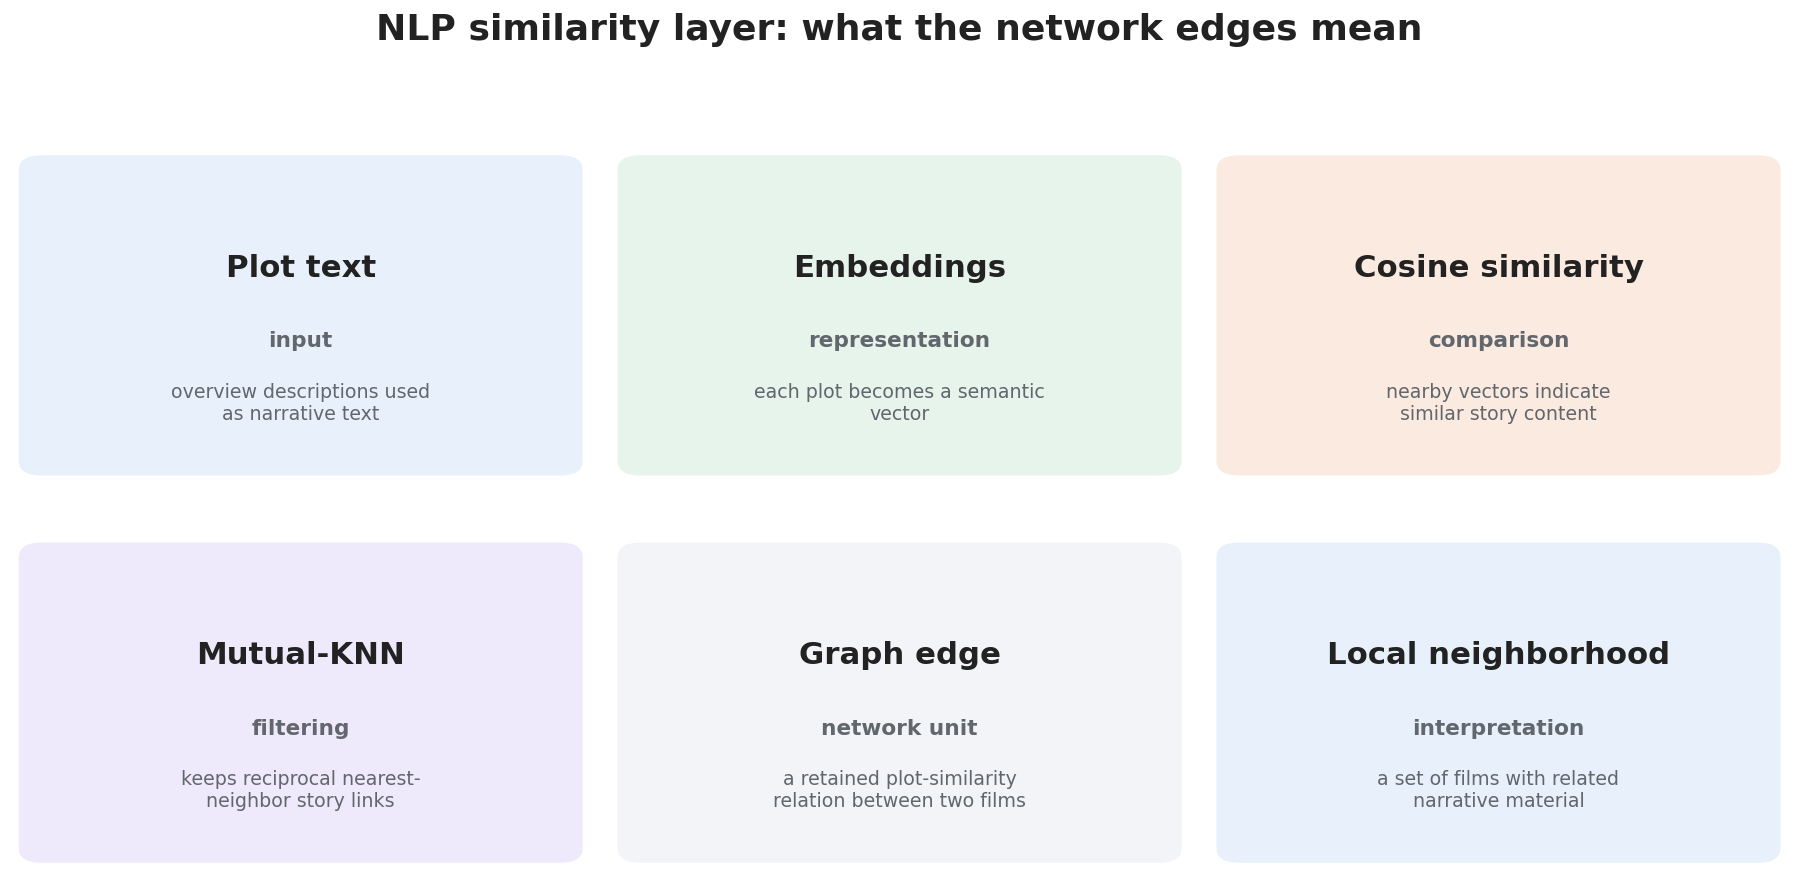

In [12]:

cards = [
    ("Plot text", "input", "overview descriptions used as narrative text", COL["light_blue"]),
    ("Embeddings", "representation", "each plot becomes a semantic vector", COL["light_green"]),
    ("Cosine similarity", "comparison", "nearby vectors indicate similar story content", COL["light_orange"]),
    ("Mutual-KNN", "filtering", "keeps reciprocal nearest-neighbor story links", COL["light_purple"]),
    ("Graph edge", "network unit", "a retained plot-similarity relation between two films", COL["light_gray"]),
    ("Local neighborhood", "interpretation", "a set of films with related narrative material", COL["light_blue"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (title, role, desc, bg) in zip(axes, cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, title, ha="center", va="center", fontsize=17, fontweight="bold")
    ax.text(0.5, 0.42, role, ha="center", va="center", fontsize=12, color=COL["muted"], fontweight="bold")
    ax.text(0.5, 0.25, wrap_text(desc, 28), ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("NLP similarity layer: what the network edges mean", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, "08_nlp_similarity_summary_cards.png")
plt.show()


## 12. Export interpretation note

In [13]:

note = """
Brick 2 — NLP similarity explanation note

This section should appear in the Methodology chapter before the network construction section.

Main message:
The thesis converts plot descriptions into semantic vectors, compares those vectors using similarity, and keeps reciprocal nearest-neighbor relations as plot-based graph edges.

Recommended main thesis figures:
1. 01_text_to_embedding_concept.png
2. 02_semantic_neighbor_cards.png
3. 04_mutual_knn_toy_example.png
4. 06_anchor_ego_neighborhood.png

Recommended appendix/supporting figures:
1. 03_high_vs_low_similarity_pairs.png
2. 05_edge_similarity_distribution.png
3. 07_embedding_space_small_sample.png
4. 08_nlp_similarity_summary_cards.png

Important wording:
This is a plot-centered semantic layer. Actor names, star power, revenue, and awards are not used to create the core story-similarity network.
""".strip()

write_text(note, "brick_02_interpretation_note.txt")
print(note)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/02_nlp_similarity/text/brick_02_interpretation_note.txt
Brick 2 — NLP similarity explanation note

This section should appear in the Methodology chapter before the network construction section.

Main message:
The thesis converts plot descriptions into semantic vectors, compares those vectors using similarity, and keeps reciprocal nearest-neighbor relations as plot-based graph edges.

Recommended main thesis figures:
1. 01_text_to_embedding_concept.png
2. 02_semantic_neighbor_cards.png
3. 04_mutual_knn_toy_example.png
4. 06_anchor_ego_neighborhood.png

Recommended appendix/supporting figures:
1. 03_high_vs_low_similarity_pairs.png
2. 05_edge_similarity_distribution.png
3. 07_embedding_space_small_sample.png
4. 08_nlp_similarity_summary_cards.png

Important wording:
This is a plot-centered semantic layer. Actor names, star power, revenue, and awards are not used to create the core story-similarity network.


## 13. Output check

In [14]:

print("Figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)

print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)

print("\nText:")
for p in sorted(TEXT_DIR.glob("*.txt")):
    print("-", p.name)


Figures:
- 01_text_to_embedding_concept.png
- 02_semantic_neighbor_cards.png
- 03_high_vs_low_similarity_pairs.png
- 04_mutual_knn_toy_example.png
- 05_edge_similarity_distribution.png
- 07_embedding_space_small_sample.png
- 08_nlp_similarity_summary_cards.png

Tables:
- 02_semantic_neighbor_cards_table.csv
- 03_high_vs_low_similarity_pairs_table.csv
- 05_edge_similarity_distribution_summary.csv
- 07_embedding_space_small_sample_coordinates.csv

Text:
- brick_02_interpretation_note.txt
